# MNIST Digit Generation with GANs: Baseline

*Building, training, and evaluating a Generative Adversarial Network (GAN) to generate handwritten digits.*

In [363]:
%pip install numpy pandas matplotlib torch torchvision torchinfo

Note: you may need to restart the kernel to use updated packages.


## Notebook Overview

This notebook trains a GAN to generate handwritten digits and compares five truncation settings across three random seeds. It examines the resulting images and measures precision and recall. **In JupyterLab, use the Table of Contents panel in the left sidebar to jump to any heading**

## Baseline objective
The objective is to establish a baseline GAN trained on the MNIST dataset using a truncation value of 1. We will evaluate the quality and diversity of the generated digits across three random seeds (42, 123 and 456)

We will compare the results and measure their variability to establish a reliable baseline for the experiments in NB2

Our goal is to establish a baseline GAN rather than reproduce a specific published result. We will use its performance as a reference for investigating the effects of different truncation values in NB2

## General Overview

We use the **MNIST dataset**, which contains images of handwritten digits. Our goal is to generate new digits with different handwriting styles.

First, we use a **GAN**, which consists of two neural networks working together:
- **Generator:** Creates new handwritten digits from random noise.
- **Discriminator:** Tries to distinguish generated digits from real ones.

Next, we use a **separate CNN** to evaluate the generated digits. It helps us measure how realistic the digits are (**precision**) and how much variety they have (**recall**).

Finally, we **visualise the results** to see the generated digits, examine their quality and variety, and understand how well the models performed.

## Effects of Random Seeds

The random seed affects the initial model weights, random noise, training data order and dropout. These differences can influence how the GAN learns and the quality of its generated images

We use three random seeds (42, 123 and 456) to check whether the baseline produces consistent results despite these random differences

## Evaluation Methods: Precision, Recall and Visual Analysis

We use three methods to evaluate how changing truncation affects the quality and diversity of generated MNIST digits.

- **Precision (Image Quality):** Measures how closely the generated images resemble real handwritten digits using features extracted by a trained CNN. Higher precision suggests that more generated images have realistic characteristics.

- **Recall (Image Diversity):** Measures how much of the variety found in real MNIST digits is represented by the generated images. Higher recall suggests that the generator produces a wider range of digit shapes and writing styles.

- **Visual Analysis:** Involves examining generated images to assess their clarity, recognisability and variety. It helps us identify blurry digits, repeated patterns and possible mode collapse that numerical scores might not fully explain.

### Why Do We Use These Methods?

Our experiment investigates how truncation affects both image quality and diversity. Precision and recall provide numerical measurements that allow us to compare different truncation values and random seeds.

Visual analysis complements these measurements by showing what the generated images actually look like. Together, these methods help us understand the trade-off between image quality and diversity and draw more reliable conclusions.


## Table of Contents
- [Notebook Overview](#notebook-overview)
- [Baseline Objective](#baseline-objective)
- [General Overview](#general-overview)
- [Effects of Random Seeds](#effects-of-random-seeds)
- [Evaluation Methods: Precision, Recall and Visual Analysis](#evaluation-methods-precision-recall-and-visual-analysis)
- [Why Do We Use These Methods?](#why-do-we-use-these-methods)

### 1. Setup and Configuration
- [1.1 Import Libraries](#11-import-libraries)
- [1.2 Choose Whether to Train or Reuse Results](#12-choose-whether-to-train-or-reuse-results)
- [1.3 Choose Where to Save Results](#13-choose-where-to-save-results)
- [1.4 Set the Truncation Experiment](#14-set-the-truncation-experiment)
- [1.5 Set Training and Model Parameters](#15-set-training-and-model-parameters)

### 2. Prepare the MNIST Dataset
- [2.1 Load the Dataset](#21-load-the-dataset)
- [2.2 Preview a Training Image](#22-preview-a-training-image)

### 3. Build the GAN
- [3.1 Define the Generator](#31-define-the-generator)
- [3.2 Define the Discriminator](#32-define-the-discriminator)
- [3.3 Create Models for Inspection](#33-create-models-for-inspection)
- [3.4 Inspect the Generator Layers](#34-inspect-the-generator-layers)
- [3.5 Inspect the Discriminator Layers](#35-inspect-the-discriminator-layers)

### 4. Set Up Loss Functions and Optimisers
- [4.1 Define the Loss Functions](#41-define-the-loss-functions)
- [4.2 Create the Optimisers](#42-create-the-optimisers)

### 5. Train or Load the GAN
- [5.1 Save Training Results](#51-save-training-results)
- [5.2 Define the Training Steps](#52-define-the-training-steps)
- [5.3 Train the GAN for One Seed](#53-train-the-gan-for-one-seed)
- [5.4 Run or Reuse the Experiments](#54-run-or-reuse-the-experiments)

### 6. Evaluate Image Quality and Diversity
- [6.1 Define an MNIST Classifier](#61-define-an-mnist-classifier)
- [6.2 Train the Classifier](#62-train-the-classifier)
- [6.3 Define Feature-Based Precision and Recall](#63-define-feature-based-precision-and-recall)
- [6.4 Evaluate the Baseline GAN](#64-evaluate-the-baseline-gan)
- [6.5 Evaluate the Baseline Across Three Random Seeds](#65-evaluate-the-baseline-across-three-random-seeds)

### 7. Visualise the Results
- [7.1 Plot Training Losses](#71-plot-training-losses)
- [7.2 View Training Progress](#72-view-training-progress)
- [7.3 Compare Final Generated Digits](#73-compare-final-generated-digits)


### 8. Baseline Results Analysis
- [8.1 Training Progress](#81-training-progress)
- [8.2 Image Quality and Diversity](#82-image-quality-and-diversity)
- [8.3 Training Losses](#83-training-losses)
- [8.4 Precision and Recall](#84-precision-and-recall)
- [8.5 Variability Across Random Seeds](#85-variability-across-random-seeds)
- [8.6 Baseline Conclusion](#86-baseline-conclusion)

## 1. Setup and Configuration

### 1.1 Import Libraries

We import the libraries used throughout the notebook. PyTorch builds and trains the neural networks, while NumPy works with arrays and random numbers. Matplotlib displays images and graphs, pandas creates tables, and `Path` handles file locations

In [229]:
import numpy as np
import torch 
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

### 1.2 Choose Whether to Train or Reuse Results

Set `QUICK = True` to use results that were saved earlier instead of training again. Set it to `False` to train new models for all three random seeds. When `QUICK` is `True`, a later cell checks that the saved files exist

In [231]:
# Change QUICK to True to run load the cache results
# Instead of training it from the beginning
QUICK = True

### 1.3 Choose Where to Save Results

This cell chooses the main folder for saved experiment files. Each truncation setting will have its own subfolder inside `results`. Keeping results in separate folders prevents experiments from getting mixed up

In [233]:
RESULTS_DIR = Path("results")

### 1.4 Set the Truncation Experiment

We will test five truncation values: 0.25, 0.5, 1, 1.5 and 2. `CURRENT_TRUNCATION` selects a position in the list, so index `2` chooses the baseline value `1`. The code also chooses a folder for the selected experiment

In [235]:
# Main experiment: Test different truncation values and analyze their effects on GAN performance
TRUNCATION = 1

# Select and create the experiment folder
EXPERIMENT_DIR = RESULTS_DIR / "baseline"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)

### 1.5 Set Training and Model Parameters

This cell collects the settings used to build and train the GAN. For example, `BATCH_SIZE` determines how many images are processed together, while `NUM_EPOCHS` controls how many times training goes through the dataset. We keep these settings fixed when comparing different truncation values

In [237]:
# 1. Dataset
num_workers = 0
BATCH_SIZE = 64

# 2. Define the Model Architecture (generator and discriminator)

# Generator
LATENT_DIM = 100
GEN_HIDDEN_DIMS = [32, 64, 128]
GEN_LEAKY_SLOPE = 0.2
GEN_DROPOUT = 0.3
GEN_OUTPUT_DIM = 784

# Discriminator
DISC_INPUT_DIM = 784
DISC_HIDDEN_DIMS = [128, 64, 32]
DISC_LEAKY_SLOPE = 0.2
DISC_DROPOUT = 0.3
DISC_OUTPUT_DIM = 1

# Create the generator and discriminator
RANDOM_SEEDS = [42, 123, 456] 

# 3. Configure the Loss Functions and Optimizers

# 3.1 Loss function hyperparameters
LABEL_SMOOTHING = False

# Real loss function
SMOOTH_REAL_LABEL = 0.9

# Fake loss function
# (no variables)

# 3.2 Optimizers
OPTIMIZERS_LEARNING_RATE = 0.002

# 4. Train the Model

Z_SIZE = 100
NUM_EPOCHS = 100
PRINT_EVERY = 400 
SAMPLE_SIZE = 16

## 2. Prepare the MNIST Dataset

### 2.1 Load the Dataset

MNIST contains pictures of handwritten digits from 0 to 9. This cell downloads the dataset and converts the images into PyTorch tensors with values between 0 and 1. Data loaders then provide the images in small batches

In [240]:
from torchvision import datasets
import torchvision.transforms as transforms

transform = transforms.ToTensor()

# load the training and testing data
train_data = datasets.MNIST(root='data', train=True, download=True, transform=transform)
test_data = datasets.MNIST(root='data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_data, batch_size=BATCH_SIZE, num_workers=num_workers, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=BATCH_SIZE, num_workers=num_workers)

### 2.2 Preview a Training Image

This cell takes a batch of MNIST training images and displays one digit. It removes the axes so the digit is easier to see. This is a quick way to check that the dataset loaded correctly

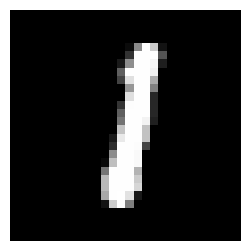

In [242]:
# Verify the dataset has loaded correctly

# Show a single image

dataiter = iter(train_loader)
images, labels = next(dataiter)
images = images.numpy()
img = np.squeeze(images[3])

fig = plt.figure(figsize=(3,3))
ax = fig.add_subplot(111)

ax.imshow(img, cmap='gray')
ax.axis('off')
plt.show()

## 3. Build the GAN

### 3.1 Define the Generator

The generator turns 100 random input numbers into a new handwritten-digit image. Its layers gradually change those numbers into 784 pixel values, which make up a 28 × 28 image. The final `Tanh` layer keeps the output between -1 and 1

In [245]:
# Define the generator

def create_generator():
    generator = nn.Sequential(
        nn.Linear(LATENT_DIM, GEN_HIDDEN_DIMS[0]), # 100 -> 32 
        nn.LeakyReLU(GEN_LEAKY_SLOPE),             # Activation function
        nn.Dropout(GEN_DROPOUT),                   # Regularization

        nn.Linear(GEN_HIDDEN_DIMS[0], GEN_HIDDEN_DIMS[1]), # 32 -> 64
        nn.LeakyReLU(GEN_LEAKY_SLOPE),                     # Activation function
        nn.Dropout(GEN_DROPOUT),                           # Regularization

        nn.Linear(GEN_HIDDEN_DIMS[1], GEN_HIDDEN_DIMS[2]), # 64 -> 128
        nn.LeakyReLU(GEN_LEAKY_SLOPE),                     # Activation function
        nn.Dropout(GEN_DROPOUT),                           # Regularization

        nn.Linear(GEN_HIDDEN_DIMS[2], GEN_OUTPUT_DIM),     # 128 -> 784
        nn.Tanh()                                          # Scale output to [-1, 1]
    )

    return generator

### 3.2 Define the Discriminator

The discriminator examines an image and produces one score about whether it looks real or generated. It first turns the 28 × 28 image into a list of 784 numbers. The remaining layers use those numbers to produce the score

In [247]:
# Define the discriminator

def create_discriminator():
    discriminator = nn.Sequential(
        nn.Flatten(), # Flatten 28x28 images into 784 features

        nn.Linear(DISC_INPUT_DIM, DISC_HIDDEN_DIMS[0]), # 784 -> 128
        nn.LeakyReLU(DISC_LEAKY_SLOPE),                 # Activation function
        nn.Dropout(DISC_DROPOUT),                       # Prevent overfitting

        nn.Linear(DISC_HIDDEN_DIMS[0], DISC_HIDDEN_DIMS[1]), # 128 -> 64
        nn.LeakyReLU(DISC_LEAKY_SLOPE),                      # Activation function 
        nn.Dropout(DISC_DROPOUT),                            # Prevent overfitting

        nn.Linear(DISC_HIDDEN_DIMS[1], DISC_HIDDEN_DIMS[2]), # 64 -> 32 
        nn.LeakyReLU(DISC_LEAKY_SLOPE),                      # Activation function
        nn.Dropout(DISC_DROPOUT),                            # Prevent overfitting 

        nn.Linear(DISC_HIDDEN_DIMS[2], DISC_OUTPUT_DIM)      # 32 -> 1 (real/fake logit)
    )

    return discriminator

### 3.3 Create Models for Inspection

This cell creates temporary versions of the generator and discriminator so we can inspect them. The random seed makes their initial settings repeatable. These temporary models are not the ones trained in the main experiments

In [249]:
# Import torchinfo for pretty print of the layers of
# the generator and discriminator
from torchinfo import summary

CURRENT_SEED = 0

torch.manual_seed(RANDOM_SEEDS[CURRENT_SEED])
np.random.seed(RANDOM_SEEDS[CURRENT_SEED])

# instantiate generator 
G_view = create_generator()

# instantiate discriminator
D_view = create_discriminator()

### 3.4 Inspect the Generator Layers

This cell displays a layer-by-layer summary of the generator. The summary shows how the size of the data changes through the network. It helps us check the architecture before training starts

In [251]:
# Display the layers of the generator
# print(G)

# Generator
print('Generator')
summary(G_view, input_size=(BATCH_SIZE, LATENT_DIM))

Generator


Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [64, 784]                 --
├─Linear: 1-1                            [64, 32]                  3,232
├─LeakyReLU: 1-2                         [64, 32]                  --
├─Dropout: 1-3                           [64, 32]                  --
├─Linear: 1-4                            [64, 64]                  2,112
├─LeakyReLU: 1-5                         [64, 64]                  --
├─Dropout: 1-6                           [64, 64]                  --
├─Linear: 1-7                            [64, 128]                 8,320
├─LeakyReLU: 1-8                         [64, 128]                 --
├─Dropout: 1-9                           [64, 128]                 --
├─Linear: 1-10                           [64, 784]                 101,136
├─Tanh: 1-11                             [64, 784]                 --
Total params: 114,800
Trainable params: 114,800
Non-trainable params: 0

### 3.5 Inspect the Discriminator Layers

This cell displays a layer-by-layer summary of the discriminator. It shows how the network processes a 28 × 28 image. This check does not train or change the discriminator

In [253]:
# Display the layers of the discriminator
# print(D)

# Discriminator
print('Discriminator')
summary(D_view, input_size=(BATCH_SIZE, 1, 28, 28))

Discriminator


Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [64, 1]                   --
├─Flatten: 1-1                           [64, 784]                 --
├─Linear: 1-2                            [64, 128]                 100,480
├─LeakyReLU: 1-3                         [64, 128]                 --
├─Dropout: 1-4                           [64, 128]                 --
├─Linear: 1-5                            [64, 64]                  8,256
├─LeakyReLU: 1-6                         [64, 64]                  --
├─Dropout: 1-7                           [64, 64]                  --
├─Linear: 1-8                            [64, 32]                  2,080
├─LeakyReLU: 1-9                         [64, 32]                  --
├─Dropout: 1-10                          [64, 32]                  --
├─Linear: 1-11                           [64, 1]                   33
Total params: 110,849
Trainable params: 110,849
Non-trainable params: 0
To

## 4. Set Up Loss Functions and Optimisers

### 4.1 Define the Loss Functions

A loss function measures how different a prediction is from its target. Here, real images have a target of 1 (or 0.9 when label smoothing is enabled), and fake images have a target of 0. These functions help calculate the errors used during GAN training

In [256]:
# The loss functions that help the discriminator distinguish 
# real from fake images

# distinguish real images
def real_loss(D_out, smooth=False):
    batch_size = D_out.size(0)

    # label smoothing
    if smooth:
        labels = torch.ones(batch_size) * SMOOTH_REAL_LABEL
    else:
        labels = torch.ones(batch_size)

    criterion = nn.BCEWithLogitsLoss()
    
    loss = criterion(D_out.squeeze(-1), labels)

    return loss

# distinguish fake images
def fake_loss(D_out):
    batch_size = D_out.size(0)
    labels = torch.zeros(batch_size)
    
    criterion = nn.BCEWithLogitsLoss()

    loss = criterion(D_out.squeeze(-1), labels)
    
    return loss

### 4.2 Create the Optimisers

An optimiser updates a model's weights so it can learn from its errors. This cell creates one Adam optimiser for the generator and another for the discriminator. Both use the learning rate chosen in the settings

In [258]:
import torch.optim as optim

def create_optimizers(G, D):
    # Create optimizers for the generator and discriminator
    g_optimizer = optim.Adam(G.parameters(), lr=OPTIMIZERS_LEARNING_RATE)
    d_optimizer = optim.Adam(D.parameters(), lr=OPTIMIZERS_LEARNING_RATE)

    return g_optimizer, d_optimizer

## 5. Train or Load the GAN

### 5.1 Save Training Results

This function saves the results of one training run to a file. It stores the generator and discriminator weights, training losses, generated sample images, and important settings. We can use the saved file later without running that training again

In [261]:
# Save the results for one random seed
def save_results(seed, G, D, losses, samples):

    torch.save({
        "seed": seed,
        "generator": G.state_dict(),
        "discriminator": D.state_dict(),
        "losses": losses,
        "samples": samples,
        "config": {
            "epochs": NUM_EPOCHS,
            "batch_size": BATCH_SIZE,
            "latent_dim": Z_SIZE,
            "truncation": TRUNCATION,
            "learning_rate": OPTIMIZERS_LEARNING_RATE,
            "label_smoothing": LABEL_SMOOTHING,
            "gen_hidden_dims": GEN_HIDDEN_DIMS,
            "disc_hidden_dims": DISC_HIDDEN_DIMS
        }
    }, EXPERIMENT_DIR / f"seed_{seed}.pt")

### 5.2 Define the Training Steps

These functions describe the two parts of a GAN training step. First, the discriminator learns to tell real images from generated ones; then, the generator learns to produce images that look real to the discriminator. Random input numbers are sampled from a range set by `TRUNCATION`

In [263]:
def train_discriminator(real_images, G, D, d_optimizer):
    batch_size = real_images.size(0)

    d_optimizer.zero_grad()

    # Train with real images
    D_real = D(real_images)
    d_real_loss = real_loss(D_real, smooth=LABEL_SMOOTHING)

    # Train with fake images
    # z = np.random.uniform(-1, 1, size=(batch_size, z_size))
    z = np.random.uniform(-TRUNCATION, TRUNCATION, size=(batch_size, Z_SIZE)) # Apply truncation
    z = torch.from_numpy(z).float()
    fake_images = G(z)

    D_fake = D(fake_images.detach())
    d_fake_loss = fake_loss(D_fake)

    # Update discriminator
    d_loss = d_real_loss + d_fake_loss
    d_loss.backward()
    d_optimizer.step()

    return d_loss


def train_generator(real_images, G, D, g_optimizer):
    batch_size = real_images.size(0)

    g_optimizer.zero_grad()

    # Generate fake images
    # z = np.random.uniform(-1, 1, size=(batch_size, z_size))
    z = np.random.uniform(-TRUNCATION, TRUNCATION, size=(batch_size, Z_SIZE)) # Apply truncation
    z = torch.from_numpy(z).float()
    fake_images = G(z)

    # Train with flipped labels
    D_fake = D(fake_images)
    g_loss = real_loss(D_fake)

    # Update generator
    g_loss.backward()
    g_optimizer.step()

    return g_loss

### 5.3 Train the GAN for One Seed

This function trains a fresh generator and discriminator using one random seed. It repeatedly updates both networks and records their losses after each epoch. It also saves sample digits made from fixed random inputs, so we can see how the images change during training

In [265]:
RESULTS_DIR.mkdir(exist_ok=True)


# Train the GAN for one random seed
def train_one_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Instantiate generator and discriminator
    G = create_generator()
    D = create_discriminator()

    # Create fresh optimizers
    g_optimizer, d_optimizer = create_optimizers(G, D)

    # Store generated images and training losses
    samples = []
    losses = []

    # Fixed random noise
    fixed_z = np.random.uniform(-1, 1, size=(SAMPLE_SIZE, Z_SIZE))
    fixed_z = torch.from_numpy(fixed_z).float()

    G.train()
    D.train()

    for epoch in range(NUM_EPOCHS):
        for batch_i, (real_images, _) in enumerate(train_loader):
            batch_size = real_images.size(0)

            # Rescale images from [0, 1] to [-1, 1]
            real_images = real_images * 2 - 1

            # Train discriminator
            d_loss = train_discriminator(
                real_images, G, D, d_optimizer
            )

            # Train generator
            g_loss = train_generator(
                real_images, G, D, g_optimizer
            )

            if batch_i % PRINT_EVERY == 0:
                print(
                    f"Seed {seed} | Epoch [{epoch+1}/{NUM_EPOCHS}] "
                    f"| d_loss: {d_loss.item():.4f} "
                    f"| g_loss: {g_loss.item():.4f}"
                )

        # Store losses after each epoch
        losses.append((d_loss.item(), g_loss.item()))

        # Generate and save sample images
        G.eval()

        with torch.no_grad():
            samples_z = G(fixed_z * TRUNCATION)
            samples.append(samples_z.cpu())

        G.train()

    return G, D, losses, samples

### 5.4 Run or Reuse the Experiments

This cell decides whether to train the GAN or reuse saved results. If `QUICK` is `True`, it checks that the required files exist for all three seeds. Otherwise, it trains and saves a separate model for each seed

In [267]:
# Train and save the GAN for each random seed
if QUICK:
    print("Loading saved results")
    
    for seed in RANDOM_SEEDS:
        checkpoint_path = EXPERIMENT_DIR / f"seed_{seed}.pt"

        if not checkpoint_path.is_file():
            raise FileNotFoundError(
                f"Missing checkpoint: {checkpoint_path}"
            )

    print("All 3 checkpoints found. Ready for evaluation.")
else:
    for seed in RANDOM_SEEDS:
        G, D, losses, samples = train_one_seed(seed)
        save_results(seed, G, D, losses, samples)

Loading saved results
All 3 checkpoints found. Ready for evaluation.


## 6. Evaluate Image Quality and Diversity

### 6.1 Define an MNIST Classifier

This cell defines a convolutional neural network (CNN) that learns to recognise handwritten digits. Its first layers find useful patterns in the images, and its final layer predicts the digit. We will also use the learned patterns to compare real and generated images

In [270]:
import torch
import torch.nn as nn

# CNN for extracting meaningful features from MNIST images
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU()
        )

        self.output = nn.Linear(128, 10)

    def forward(self, x):
        features = self.features(x)
        logits = self.output(features)

        return logits, features


### 6.2 Train the Classifier

This cell trains the CNN on real MNIST images and their correct digit labels. It repeats the training for five epochs and prints the average loss each time. Afterwards, it switches the CNN to evaluation mode

In [336]:
# Initialize the CNN
torch.manual_seed(777)

classifier = MNISTClassifier()

# Path for saving and loading the classifier
CLASSIFIER_PATH = RESULTS_DIR / "mnist_classifier.pt"

if CLASSIFIER_PATH.is_file():
    # Load the previously trained classifier
    classifier.load_state_dict(
        torch.load(
            CLASSIFIER_PATH,
            map_location="cpu",
            weights_only=True
        )
    )

    print("Loaded saved MNIST classifier.")

elif QUICK:
    raise FileNotFoundError(
        f"Classifier checkpoint not found: {CLASSIFIER_PATH}"
    )

else:
    # Configure classifier training
    optimizer = torch.optim.Adam(
        classifier.parameters(), lr=0.001
    )

    criterion = nn.CrossEntropyLoss()

    NUM_CLASSIFIER_EPOCHS = 5

    # Train the classifier
    for epoch in range(NUM_CLASSIFIER_EPOCHS):
        classifier.train()
        total_loss = 0

        for images, labels in train_loader:
            optimizer.zero_grad()

            # Classify real MNIST digits
            logits, _ = classifier(images)

            # Calculate loss
            loss = criterion(logits, labels)

            # Update model weights
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch [{epoch + 1}/{NUM_CLASSIFIER_EPOCHS}] "
            f"| Loss: {total_loss / len(train_loader):.4f}"
        )

    # Save the trained classifier
    CLASSIFIER_PATH.parent.mkdir(parents=True, exist_ok=True)
    torch.save(classifier.state_dict(), CLASSIFIER_PATH)

    print("MNIST classifier saved.")

# Prepare the classifier for evaluation
classifier.eval()

Loaded saved MNIST classifier.


MNISTClassifier(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=1568, out_features=128, bias=True)
    (8): ReLU()
  )
  (output): Linear(in_features=128, out_features=10, bias=True)
)

### 6.3 Define Feature-Based Precision and Recall

These helper functions turn real and generated images into lists of learned features. They compare nearby features to measure precision (how closely generated images resemble real ones) and recall (how much of the real images' variety is represented). This provides a numerical comparison alongside the visual results

In [274]:
import torch
import pandas as pd

# Use the trained CNN to extract image features
feature_extractor = classifier.features
feature_extractor.eval()


# Extract features from real MNIST images
def extract_real_features(feature_extractor, test_loader, num_samples=4000):
    feature_extractor.eval()
    device = next(feature_extractor.parameters()).device

    features = []

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)

            batch_features = feature_extractor(images)
            features.append(batch_features.cpu())

            if sum(len(f) for f in features) >= num_samples:
                break

    return torch.cat(features, dim=0)[:num_samples]


# Extract features from generated MNIST images
def extract_fake_features(
    G, feature_extractor, truncation,
    num_samples=2000, batch_size=128
):
    G.eval()
    feature_extractor.eval()

    device = next(G.parameters()).device
    feature_device = next(feature_extractor.parameters()).device

    rng = torch.Generator().manual_seed(999)
    features = []

    with torch.no_grad():
        for i in range(0, num_samples, batch_size):
            n = min(batch_size, num_samples - i)

            # Generate latent noise
            z = torch.rand(n, Z_SIZE, generator=rng) * 2 - 1
            z = z.to(device) * truncation

            # Generate images
            fake_images = G(z)

            # Reshape and rescale to [0, 1]
            fake_images = fake_images.reshape(-1, 1, 28, 28)
            fake_images = (fake_images + 1) / 2

            # Extract learned features
            batch_features = feature_extractor(
                fake_images.to(feature_device)
            )

            features.append(batch_features.cpu())

    return torch.cat(features, dim=0)


# Calculate distance to kth nearest neighbour
def calculate_radii(features, k=5, batch_size=256):
    features = features.cpu().float()

    if len(features) <= k:
        raise ValueError("Not enough samples for k neighbours.")

    radii = []

    for i in range(0, len(features), batch_size):
        end = min(i + batch_size, len(features))

        distances = torch.cdist(
            features[i:end], features
        )

        # Exclude each image from its own neighbours
        row_indices = torch.arange(end - i)
        col_indices = torch.arange(i, end)
        distances[row_indices, col_indices] = float("inf")

        kth_distance = distances.topk(
            k, largest=False
        ).values[:, -1]

        radii.append(kth_distance)

    return torch.cat(radii)


# Measure how many query samples fall within reference neighbourhoods
def calculate_coverage(
    queries, references, radii, batch_size=256
):
    queries = queries.cpu().float()
    references = references.cpu().float()

    covered = 0

    for i in range(0, len(queries), batch_size):
        distances = torch.cdist(
            queries[i:i + batch_size], references
        )

        matches = (
            distances <= radii.unsqueeze(0)
        ).any(dim=1)

        covered += matches.sum().item()

    return covered / len(queries)


# Calculate generative precision and recall
def calculate_precision_recall(
    real_features, fake_features, k=5
):
    real_radii = calculate_radii(real_features, k)
    fake_radii = calculate_radii(fake_features, k)

    # Precision: generated images near real images
    precision = calculate_coverage(
        fake_features, real_features, real_radii
    )

    # Recall: real images covered by generated images
    recall = calculate_coverage(
        real_features, fake_features, fake_radii
    )

    return precision, recall

### 6.4 Evaluate the Baseline GAN

First, this cell compares two groups of real MNIST images to establish a reference. Next, it loads the baseline generator (truncation 1, seed 42) and compares its images with real images. Both comparisons report precision and recall

In [276]:
# Evaluate the baseline GAN using Precision and Recall
NUM_SAMPLES = 2000

# Extract real MNIST features
all_real_features = extract_real_features(
    feature_extractor, test_loader,
    num_samples=NUM_SAMPLES * 2
)

# Split real features into two independent groups
real_1 = all_real_features[:NUM_SAMPLES]
real_2 = all_real_features[NUM_SAMPLES:]

# Load the baseline GAN
checkpoint = torch.load(
    RESULTS_DIR / "baseline" / f"seed_{RANDOM_SEEDS[0]}.pt",
    map_location="cpu",
    weights_only=True
)

G = create_generator()
G.load_state_dict(checkpoint["generator"])
G.eval()

# Extract features from baseline GAN images
fake_features = extract_fake_features(
    G, feature_extractor,
    truncation=1.0,
    num_samples=NUM_SAMPLES
)

# Real vs Real baseline
real_precision, real_recall = calculate_precision_recall(
    real_1, real_2
)

# Real vs Generated GAN
gan_precision, gan_recall = calculate_precision_recall(
    real_1, fake_features
)

print("Real vs Real (Reference)")
print(f"Precision: {real_precision:.4f}")
print(f"Recall: {real_recall:.4f}")

print("\nReal vs Generated (Baseline GAN)")
print(f"Precision: {gan_precision:.4f}")
print(f"Recall: {gan_recall:.4f}")

Real vs Real (Reference)
Precision: 0.9485
Recall: 0.9430

Real vs Generated (Baseline GAN)
Precision: 0.8825
Recall: 0.1940


### 6.5 Evaluate the Baseline Across Three Random Seeds

This cell evaluates the baseline GAN using three random seeds (42, 123 and 456). It loads each trained generator and calculates its precision and recall. The table shows the average scores and standard deviations across the three seeds

In [278]:
# Evaluate precision and recall for the baseline experiment
evaluation_results = []

for seed in RANDOM_SEEDS:

    # Load trained generator
    checkpoint = torch.load(
        EXPERIMENT_DIR / f"seed_{seed}.pt",
        map_location="cpu",
        weights_only=True
    )

    G = create_generator()
    G.load_state_dict(checkpoint["generator"])
    G.eval()

    # Extract generated image features
    fake_features = extract_fake_features(
        G,
        feature_extractor,
        truncation=TRUNCATION,
        num_samples=NUM_SAMPLES
    )

    # Calculate precision and recall
    precision, recall = calculate_precision_recall(
        real_1, fake_features
    )

    evaluation_results.append({
        "seed": seed,
        "precision": precision,
        "recall": recall
    })

    print(
        f"Seed: {seed} "
        f"| Precision: {precision:.4f} "
        f"| Recall: {recall:.4f}"
    )

    del G, fake_features


# Summarise results across the three random seeds
df = pd.DataFrame(evaluation_results)

summary = df[["precision", "recall"]].agg(["mean", "std"])

display(summary.round(4))

Seed: 42 | Precision: 0.8825 | Recall: 0.1940
Seed: 123 | Precision: 0.9060 | Recall: 0.1965
Seed: 456 | Precision: 0.9090 | Recall: 0.1830


,precision,recall
mean,0.8992,0.1912
std,0.0145,0.0072


## 7. Visualise the Results

### 7.1 Plot Training Losses

This cell plots the saved generator and discriminator losses for each seed. The lines show how the losses change over training epochs. They help us compare training behaviour, although the loss curves alone cannot tell us how realistic the digits look

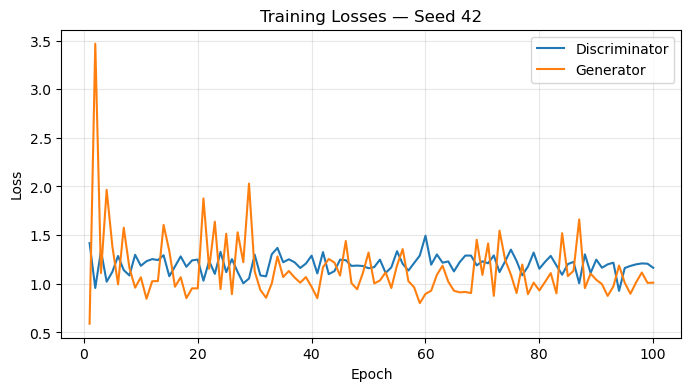

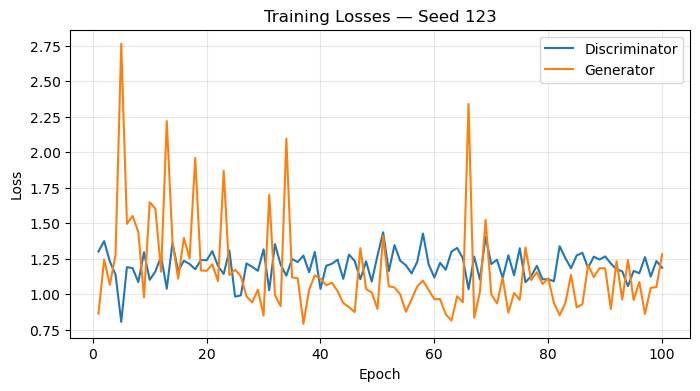

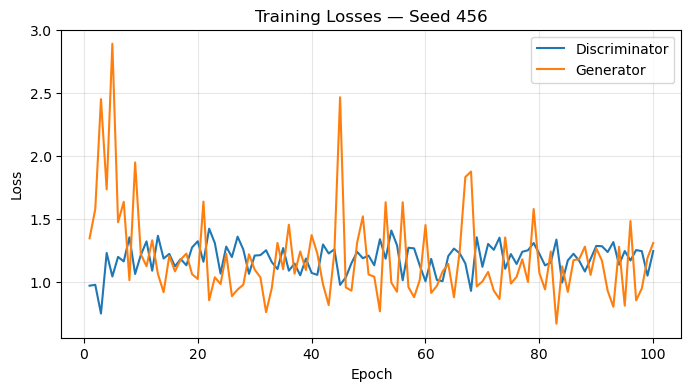

In [281]:
# Plot training losses for a specific seed

def plot_training_losses(seed):

    checkpoint = torch.load(
        EXPERIMENT_DIR / f"seed_{seed}.pt",
        map_location="cpu",
        weights_only=True
    )

    losses = np.array(checkpoint["losses"])
    epochs = np.arange(1, len(losses) + 1)

    fig, ax = plt.subplots(figsize=(8, 4))

    ax.plot(epochs, losses[:, 0], label="Discriminator")
    ax.plot(epochs, losses[:, 1], label="Generator")

    ax.set_title(f"Training Losses — Seed {seed}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.show()

for seed in RANDOM_SEEDS:
    plot_training_losses(seed)

### 7.2 View Training Progress

This cell displays digits saved at different points during training. Each row shows a different training stage, making changes in the generated images easier to notice. It displays the progress separately for each random seed

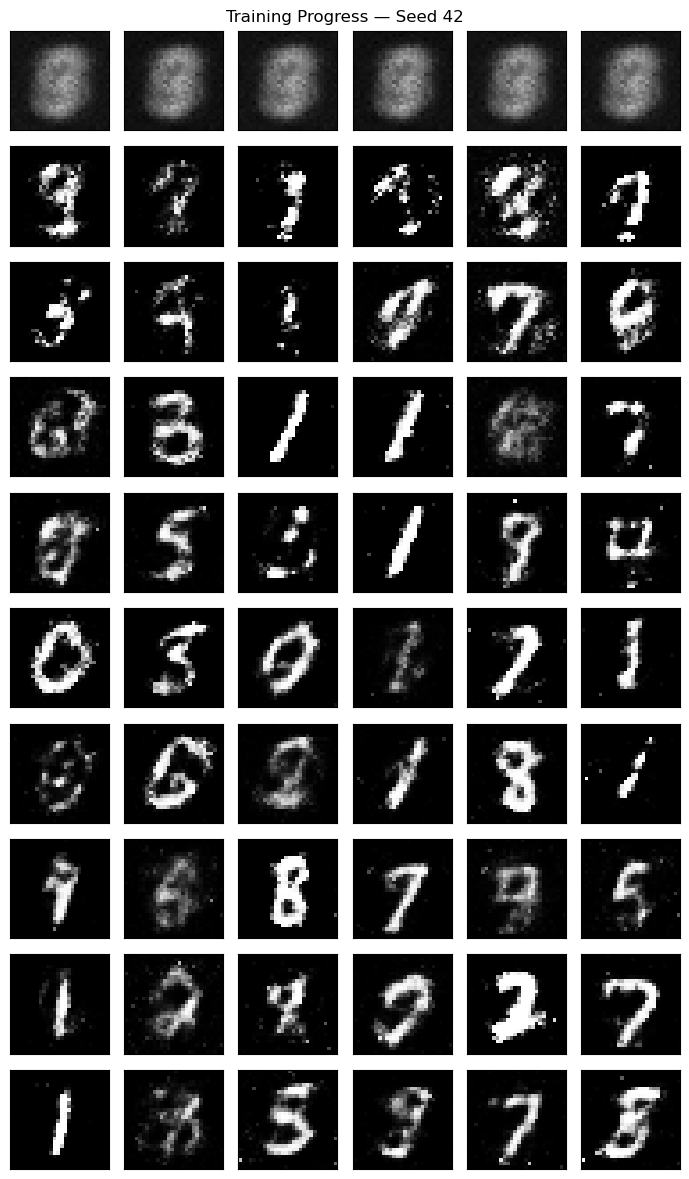

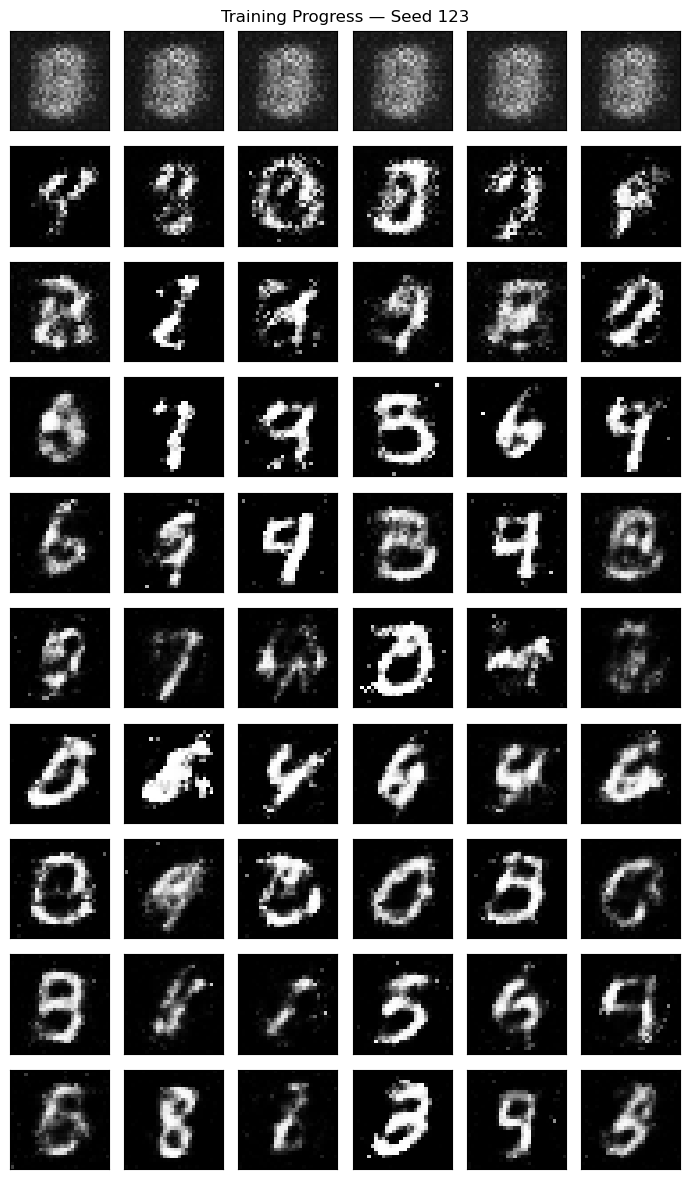

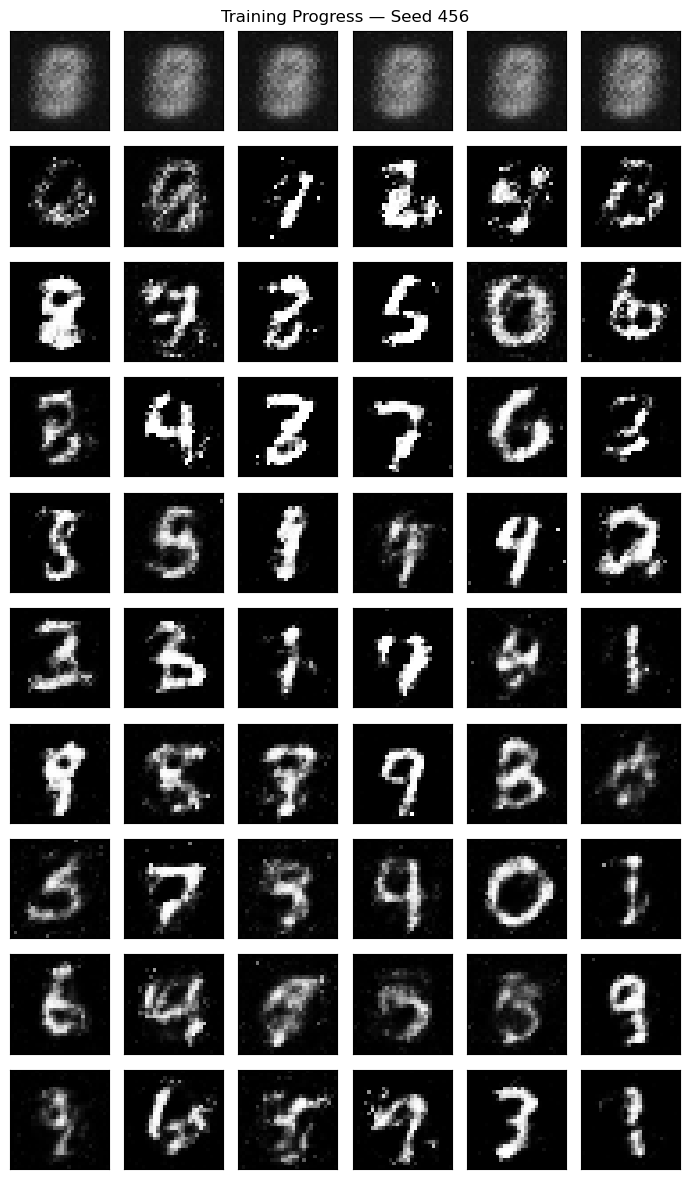

In [283]:
# Visualize generated images across training epochs

def view_training_progress(seed):
    checkpoint = torch.load(
        EXPERIMENT_DIR / f"seed_{seed}.pt",
        map_location="cpu",
        weights_only=True
    )

    samples = checkpoint["samples"]

    rows = min(10, len(samples))  # Display up to 10 training stages
    cols = min(6, len(samples[0]))

    # Select evenly spaced stages, including the final one
    stages = np.linspace(0, len(samples) - 1, rows, dtype=int)
    image_indices = np.linspace(0, len(samples[0]) - 1, cols, dtype=int)

    fig, axes = plt.subplots(
        figsize=(7, 12),
        nrows=rows,
        ncols=cols,
        sharex=True,
        sharey=True,
        squeeze=False
    )

    for stage, ax_row in zip(stages, axes):
        for img_idx, ax in zip(image_indices, ax_row):
            img = samples[stage][img_idx].detach().cpu().numpy()
            ax.imshow(img.reshape((28, 28)), cmap="Greys_r", vmin=-1, vmax=1)
            ax.xaxis.set_visible(False)
            ax.yaxis.set_visible(False)

    fig.suptitle(f"Training Progress — Seed {seed}")
    plt.tight_layout()
    plt.show()

for seed in RANDOM_SEEDS: 
    view_training_progress(seed)

### 7.3 Compare Final Generated Digits

This cell shows the final generated digits from the selected experiment. For each random seed, it displays 16 images in a 4 × 4 grid. These grids help us visually compare clarity, repetition, and diversity

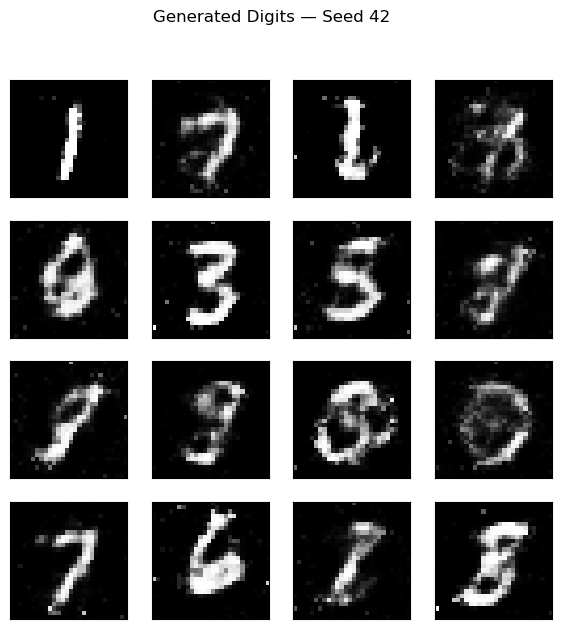

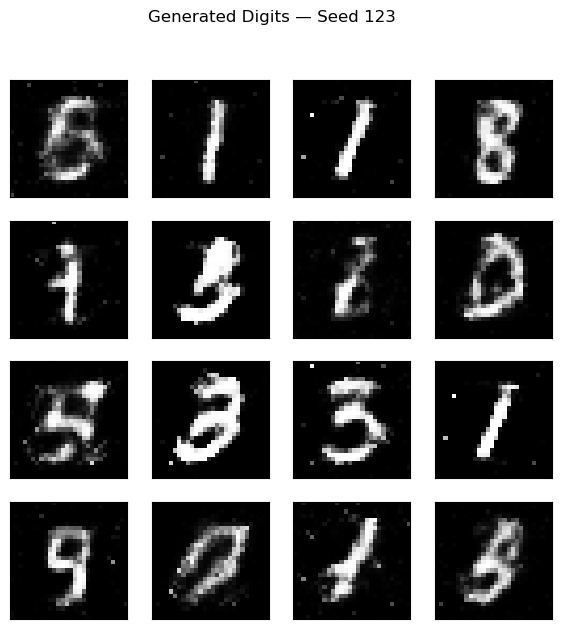

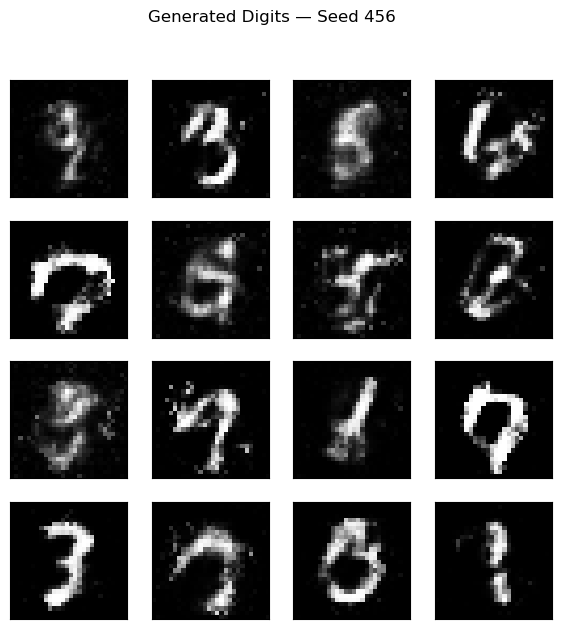

In [285]:
# View generated images for a specific seed

def view_samples(seed):

    checkpoint = torch.load(
        EXPERIMENT_DIR / f"seed_{seed}.pt",
        map_location="cpu",
        weights_only=True
    )

    samples = checkpoint["samples"]

    fig, axes = plt.subplots(
        figsize=(7, 7),
        nrows=4, ncols=4,
        sharey=True, sharex=True
    )

    for ax, img in zip(axes.flatten(), samples[-1]):
        img = img.detach().cpu().numpy()
        ax.xaxis.set_visible(False)
        ax.yaxis.set_visible(False)
        ax.imshow(img.reshape((28, 28)), cmap="Greys_r")

    fig.suptitle(f"Generated Digits — Seed {seed}")
    plt.show()


for seed in RANDOM_SEEDS:
    view_samples(seed)

## 8. Discussion and Conclusions

### 8.1 Training Progress

At the beginning of training, all three seeds produce blurry, nearly identical images. As training progresses, the generator learns to produce recognisable handwritten digits with different shapes and writing styles

By the end of training, all three seeds produce a variety of digits, although some remain blurry or distorted. This shows that the GAN has learned useful patterns from the MNIST dataset but still struggles to generate consistently clear images

### 8.2 Image Quality and Diversity

- **Seed 42:** Produces several recognisable digits with different shapes and writing styles. Some images are clear, while others contain noise or distorted features

- **Seed 123:** Generates a variety of recognisable digits, although some are blurry or difficult to identify

- **Seed 456:** Also produces different digits, but several images appear blurry or distorted

Overall, all three seeds generate different digits rather than repeatedly producing one identical image. However, some digit shapes appear more frequently than others, suggesting that the generator may not fully represent the diversity of the MNIST dataset


### 8.3 Training Losses

The generator and discriminator losses fluctuate throughout training for all three seeds. The generator shows several sharp increases in loss, particularly during the early epochs

Despite these fluctuations, neither loss shows a continuous increase or decrease towards the end of training. This suggests that training remains relatively stable, although the loss curves alone cannot confirm the quality of the generated images


### 8.4 Precision and Recall

| Seed | Precision | Recall |
|---|---:|---:|
| **42** | 0.8825 | 0.1940 |
| **123** | 0.9060 | 0.1965 |
| **456** | 0.9090 | 0.1830 |
| **Mean** | **0.8992** | **0.1912** |
| **Standard deviation** | **0.0145** | **0.0072** |

The average precision is **0.8992**, suggesting that the generated images generally resemble real MNIST digits according to the evaluation metric

However, the average recall is only **0.1912**, suggesting that the generator covers a limited part of the real dataset's diversity


### 8.5 Variability Across Random Seeds

The results show relatively small differences between the three seeds

- **Precision:** Ranges from 0.8825 to 0.9090, giving a spread of **0.0265** and a standard deviation of **0.0145**

- **Recall:** Ranges from 0.1830 to 0.1965, giving a spread of **0.0135** and a standard deviation of **0.0072**

Seed 456 achieves the highest precision but the lowest recall, while seed 123 achieves the highest recall

The relatively small standard deviations suggest that the baseline produces reasonably consistent evaluation scores across the three seeds


### 8.6 Baseline Conclusion

The baseline GAN successfully generates recognisable handwritten digits across all three random seeds, although some images remain blurry or distorted

The results show relatively high precision but low recall, suggesting that the generator produces realistic-looking digits within a limited range of the MNIST dataset's diversity

The small differences between the three seeds indicate reasonably consistent performance. These results establish a baseline for comparing the effects of different truncation values in NB2
